Proyek Klasifikasi Gambar: mikoajkolman/pokemon-images-first-generation17000-files

Nama: ASEP HARYANA SAPUTRA

Email: superaseph@gmail.com

ID Dicoding: mytheclipse

## 1. Persiapan Lingkungan

Mengimpor semua pustaka yang diperlukan dan mengatur seed untuk reproduksibilitas.

In [20]:
!pip install -r requirements.txt

In [21]:
# Import semua pustaka di awal
import os
import shutil
import zipfile
import random
import io
import logging
import traceback
import time
import psutil
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
import splitfolders  # untuk split dataset

# Keras / TF
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from tensorflow.keras.optimizers import AdamW

# Sklearn
from sklearn.metrics import confusion_matrix, classification_report

# Widget interaktif
import ipywidgets as widgets
from IPython.display import display, clear_output

# Konfigurasi global
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Optimasi performa TF
os.environ["TF_DATA_AUTOTUNE_RAM_BUDGET"] = "4000000000"
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'

# Gunakan mixed precision untuk mempercepat training (jika GPU mendukung)
tf.keras.mixed_precision.set_global_policy('mixed_float16')

print(f"Setup selesai. IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}")

Setup selesai. IMG_SIZE=(256, 256), BATCH_SIZE=32


## 2. Ekstraksi Dataset

Dataset disediakan dalam file `pokemon.zip`. Ekstrak ke folder `dataset_raw`.

In [22]:
zip_filename = 'pokemon.zip'
extract_dir = 'dataset_raw'

# Ekstrak hanya jika folder belum ada atau kosong
if os.path.exists(extract_dir) and len(os.listdir(extract_dir)) > 0:
    print(f"Folder {extract_dir} sudah ada dan tidak kosong. Ekstraksi dilewati.")
else:
    if os.path.exists(extract_dir):
        shutil.rmtree(extract_dir)
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Ekstraksi selesai.")

Folder dataset_raw sudah ada dan tidak kosong. Ekstraksi dilewati.


## 3. Pembersihan Data

Langkah-langkah:
- Gabungkan kelas duplikat (misal 'Mr. Mime' dan 'MrMime').
- Hapus file non-gambar (selain .jpg, .jpeg, .png, .bmp).
- Hapus file gambar corrupt.
- Normalisasi metadata gambar (konversi ke RGB, hapus profil ICC).

In [23]:
# Tentukan direktori utama dataset
base_dir = os.path.join(extract_dir, 'pokemon')
if not os.path.exists(base_dir):
    base_dir = extract_dir  # jika tidak ada subfolder pokemon
print(f"Direktori utama: {base_dir}")

# 1. Gabungkan kelas duplikat
duplicate_map = {'Mr. Mime': 'MrMime'}
for src, dst in duplicate_map.items():
    src_path = os.path.join(base_dir, src)
    dst_path = os.path.join(base_dir, dst)
    if os.path.exists(src_path):
        if os.path.exists(dst_path):
            # Pindahkan semua file dari src ke dst
            for f in os.listdir(src_path):
                shutil.move(os.path.join(src_path, f), os.path.join(dst_path, f))
            shutil.rmtree(src_path)
            print(f"Digabungkan {src} ke {dst}")
        else:
            os.rename(src_path, dst_path)
            print(f"Diganti nama {src} -> {dst}")

# 2. Hapus file non-gambar dan corrupt
valid_ext = ('.jpg', '.jpeg', '.png', '.bmp')
removed = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        ext = os.path.splitext(file)[1].lower()
        if ext not in valid_ext:
            os.remove(fpath)
            removed += 1
            continue
        try:
            with Image.open(fpath) as img:
                img.verify()  # cek integritas
        except Exception:
            os.remove(fpath)
            removed += 1
print(f"File dihapus (ekstensi tidak valid/corrupt): {removed}")

# 3. Bersihkan folder kelas yang kosong
for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath) and len(os.listdir(dpath)) == 0:
        shutil.rmtree(dpath)
        print(f"Folder kosong dihapus: {d}")

# 4. Normalisasi metadata (konversi ke RGB, hapus ICC profile)
sanitized = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        try:
            with Image.open(fpath) as img:
                if img.mode != 'RGB' or 'icc_profile' in img.info:
                    img = img.convert('RGB')
                    img.save(fpath, 'JPEG', quality=95, optimize=True)
                    sanitized += 1
        except Exception:
            pass
print(f"Gambar dinormalisasi: {sanitized}")

# Hitung total gambar dan kelas
class_counts = {}
total_images = 0
for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath):
        cnt = len(os.listdir(dpath))
        class_counts[d] = cnt
        total_images += cnt
print(f"Total gambar valid: {total_images} dari {len(class_counts)} kelas")

Direktori utama: dataset_raw/pokemon
File dihapus (ekstensi tidak valid/corrupt): 0
Gambar dinormalisasi: 0
Total gambar valid: 16485 dari 142 kelas


## 4. Pembagian Dataset (Train:Validation:Test = 60:20:20)

Menggunakan library `split-folders` untuk membagi secara proporsional.

In [24]:
output_dir = 'dataset_split'
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

splitfolders.ratio(
    base_dir,
    output=output_dir,
    seed=SEED,
    ratio=(0.6, 0.2, 0.2),
    group_prefix=None
)

train_dir = os.path.join(output_dir, 'train')
val_dir = os.path.join(output_dir, 'val')
test_dir = os.path.join(output_dir, 'test')

def count_images(path):
    return sum(len(files) for _, _, files in os.walk(path))

print(f"Train set: {count_images(train_dir)} gambar")
print(f"Validation set: {count_images(val_dir)} gambar")
print(f"Test set: {count_images(test_dir)} gambar")

Copying files: 16485 files [00:04, 3554.04 files/s]

Train set: 9835 gambar
Validation set: 3239 gambar
Test set: 3411 gambar


## 5. Persiapan Data Loader dengan Augmentasi

Menggunakan `image_dataset_from_directory` untuk membaca gambar.  
Augmentasi hanya diterapkan pada data training, dengan intensitas yang dikurangi agar tidak merusak fitur.

In [25]:
# Load dataset
train_ds = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=None,
    label_mode='categorical',
    shuffle=True,
    seed=SEED
)
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

# Batching
train_ds = train_ds.batch(BATCH_SIZE, drop_remainder=True)
val_ds = image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)
test_ds = image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)

print(f"Jumlah kelas: {NUM_CLASSES}")
print(f"Contoh kelas: {class_names[:5]}...")

# Augmentasi untuk training (enhanced)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.1),
])

# Fungsi preprocessing (sesuai kebutuhan MobileNetV3)
def preprocess(images, labels):
    return preprocess_input(images), labels

def augment_and_preprocess(images, labels):
    x = data_augmentation(images)
    return preprocess_input(x), labels

# Terapkan augmentasi pada training, preprocessing pada val/test
AUTOTUNE = tf.data.AUTOTUNE
train_generator = train_ds.map(augment_and_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
validation_generator = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_generator = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

Found 9835 files belonging to 142 classes.
Found 3239 files belonging to 142 classes.
Found 3411 files belonging to 142 classes.
Jumlah kelas: 142
Contoh kelas: ['Abra', 'Aerodactyl', 'Alakazam', 'Arbok', 'Arcanine']...


## 6. Visualisasi Sampel Data (dengan Augmentasi)

Menampilkan beberapa gambar dari training set yang telah diaugmentasi.

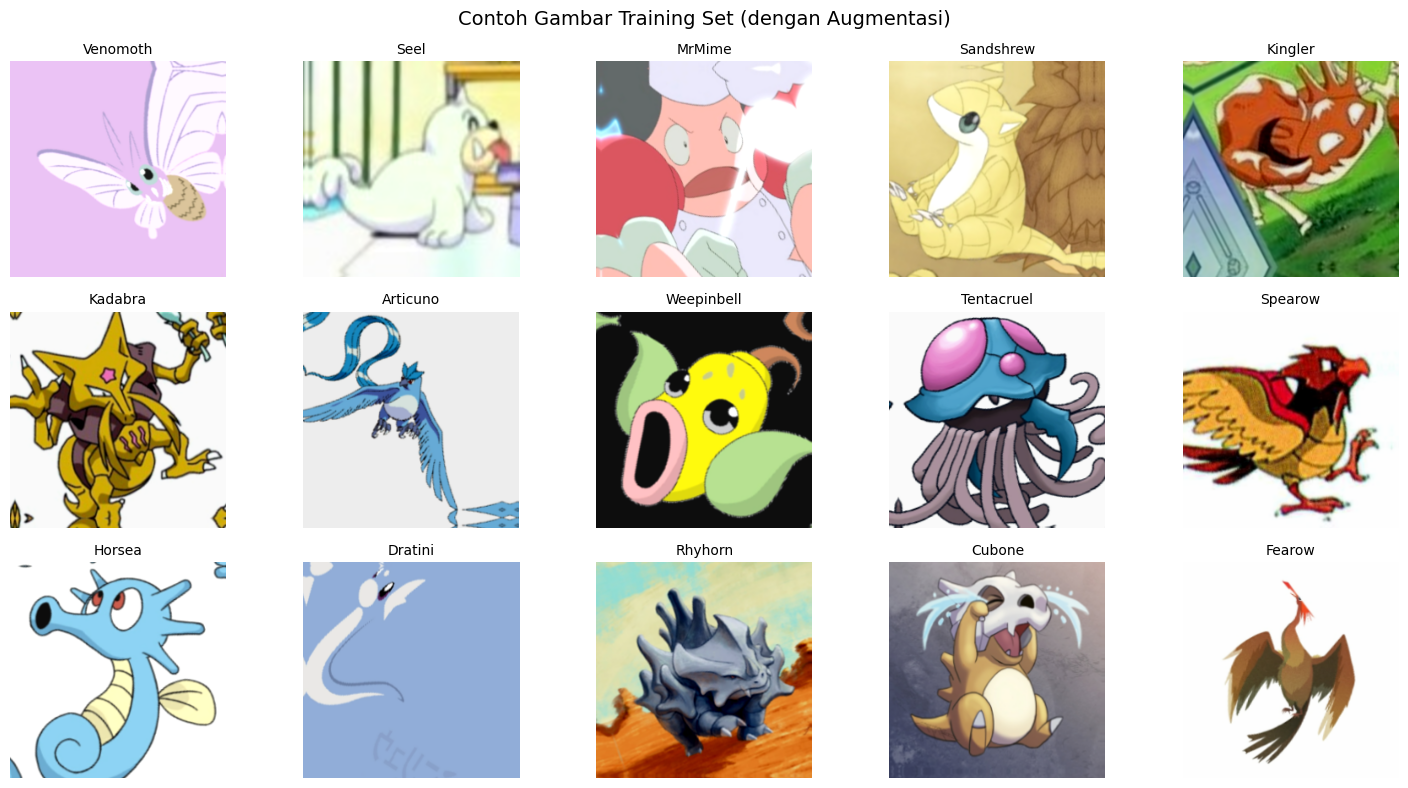

In [26]:
sample_images, sample_labels = next(iter(train_generator))

plt.figure(figsize=(15, 8))
for i in range(15):
    plt.subplot(3, 5, i+1)
    img_np = sample_images[i].numpy().astype("uint8")
    plt.imshow(img_np)
    label_idx = np.argmax(sample_labels[i])
    plt.title(class_names[label_idx], fontsize=10)
    plt.axis('off')
plt.suptitle('Contoh Gambar Training Set (dengan Augmentasi)', fontsize=14)
plt.tight_layout()
plt.show()

## 7. Penanganan Ketidakseimbangan Kelas dengan Sample Weight

Hitung bobot untuk setiap kelas berdasarkan frekuensi di training set, lalu tambahkan ke pipeline data.

In [27]:
# Hitung jumlah sampel per kelas di training
train_class_counts = Counter()
for class_name in class_names:
    folder = os.path.join(train_dir, class_name)
    if os.path.exists(folder):
        train_class_counts[class_name] = len(os.listdir(folder))

total_samples = sum(train_class_counts.values())
class_weights_list = []
for class_name in class_names:
    count = train_class_counts.get(class_name, 1)
    weight = total_samples / (NUM_CLASSES * count)
    # Batasi bobot maksimum agar tidak terlalu ekstrem
    weight = min(weight, 5.0)
    class_weights_list.append(weight)

class_weights_tensor = tf.constant(class_weights_list, dtype=tf.float32)

# Fungsi untuk menambahkan sample weight ke dataset
def add_sample_weight(image, label):
    class_indices = tf.argmax(label, axis=-1)
    sample_weights = tf.gather(class_weights_tensor, class_indices)
    return image, label, sample_weights

# Terapkan sample weight pada training generator
train_generator = train_generator.map(add_sample_weight, num_parallel_calls=AUTOTUNE)

# Tampilkan statistik bobot
print("Bobot kelas:")
for i, name in enumerate(class_names[:10]):
    print(f"{name}: {class_weights_list[i]:.4f}")
print("...")

Bobot kelas:
Abra: 1.9239
Aerodactyl: 1.3581
Alakazam: 1.3581
Arbok: 0.8995
Arcanine: 1.4429
Articuno: 1.2593
Beedrill: 1.3319
Bellsprout: 0.8880
Blastoise: 0.8148
Bulbasaur: 0.7871
...


## 8. Membangun Model CNN dengan Transfer Learning

Menggunakan MobileNetV3Large sebagai basis, ditambah layer klasifikasi yang lebih dalam dan dropout lebih besar untuk mengurangi overfitting.

In [28]:
def create_model():
    base_model = MobileNetV3Large(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # bekukan dulu

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(1024),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')
    ])
    return model

model = create_model()
model.summary()

/home/asephs/venvs/ml311/lib/python3.11/site-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Large (Functional)   │ (None, 8, 8, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       984,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 142)            │        72,846 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,584,206 (17.49 MB)

 Trainable params: 1,584,782 (6.05 MB)

 Non-trainable params: 2,999,424 (11.44 MB)

## 9. Callbacks

Menggunakan ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger, dan TensorBoard.

In [29]:
# Direktori untuk logs
log_dir = "logs/fit/" + time.strftime("%Y%m%d-%H%M%S")
os.makedirs("submission", exist_ok=True)

checkpoint = callbacks.ModelCheckpoint(
    'submission/best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stop = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

csv_logger = callbacks.CSVLogger('submission/training_log.csv')
tensorboard = callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

callbacks_list = [checkpoint, early_stop, reduce_lr, csv_logger, tensorboard]

## 10. Pelatihan Model (Fase 1: Head Saja)

Melatih layer klasifikasi terlebih dahulu dengan base model dibekukan. Menggunakan optimizer AdamW dengan weight decay.

In [30]:
model.compile(
    optimizer=AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

history1 = model.fit(
    train_generator,
    epochs=50,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 1/50


2026-02-16 13:49:51.578020: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4424', 568 bytes spill stores, 568 bytes spill loads

2026-02-16 13:49:51.909823: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4533', 340 bytes spill stores, 340 bytes spill loads

2026-02-16 13:49:52.006723: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4533', 60 bytes spill stores, 60 bytes spill loads

2026-02-16 13:49:52.016828: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4533', 32 bytes spill stores, 32 bytes spill loads

2026-02-16 13:49:52.232528: I extern

306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.1549 - loss: 4.3191

2026-02-16 13:50:13.653451: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1797', 256 bytes spill stores, 256 bytes spill loads




Epoch 1: val_accuracy improved from None to 0.67389, saving model to submission/best_model.keras

Epoch 1: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 33s 74ms/step - accuracy: 0.2867 - loss: 3.3008 - val_accuracy: 0.6739 - val_loss: 1.2736 - learning_rate: 0.0010
Epoch 2/50
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.5298 - loss: 1.8875
Epoch 2: val_accuracy improved from 0.67389 to 0.75681, saving model to submission/best_model.keras

Epoch 2: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.5510 - loss: 1.7821 - val_accuracy: 0.7568 - val_loss: 0.9360 - learning_rate: 0.0010
Epoch 3/50
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.6020 - loss: 1.5212
Epoch 3: val_accuracy improved from 0.75681 to 0.77908, saving model to submission/best_model.keras

Epoch 3: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 22s 68ms/step - accuracy

## 11. Fine-Tuning (Fase 2: Semua Layer)

Membuka semua layer base model dan melanjutkan pelatihan dengan learning rate sangat kecil.

In [31]:
# Unfreeze seluruh base model
base_model = model.layers[0]
base_model.trainable = True

# Kompilasi ulang dengan LR lebih rendah
model.compile(
    optimizer=AdamW(learning_rate=1e-5, weight_decay=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Lanjutkan training
history_fine = model.fit(
    train_generator,
    epochs=150,
    initial_epoch=history1.epoch[-1] + 1,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 49/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6850 - loss: 1.2037
Epoch 49: val_accuracy improved from 0.86757 to 0.87005, saving model to submission/best_model.keras

Epoch 49: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 60s 82ms/step - accuracy: 0.7020 - loss: 1.1063 - val_accuracy: 0.8700 - val_loss: 0.5128 - learning_rate: 1.0000e-05
Epoch 50/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.7523 - loss: 0.8956
Epoch 50: val_accuracy improved from 0.87005 to 0.88923, saving model to submission/best_model.keras

Epoch 50: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 25s 78ms/step - accuracy: 0.7630 - loss: 0.8447 - val_accuracy: 0.8892 - val_loss: 0.4510 - learning_rate: 1.0000e-05
Epoch 51/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7899 - loss: 0.7370
Epoch 51: val_accuracy improved from 0.88923 to 0.89697, saving model to submission/best_model.keras

Epoch 5

2026-02-16 14:10:54.048071: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 12601088 bytes after encountering the first element of size 12601088 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8383 - loss: 0.5543
Epoch 53: val_accuracy improved from 0.90037 to 0.90347, saving model to submission/best_model.keras

Epoch 53: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 27s 85ms/step - accuracy: 0.8415 - loss: 0.5287 - val_accuracy: 0.9035 - val_loss: 0.3741 - learning_rate: 1.0000e-05
Epoch 54/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8531 - loss: 0.4855
Epoch 54: val_accuracy improved from 0.90347 to 0.90470, saving model to submission/best_model.keras

Epoch 54: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 27s 84ms/step - accuracy: 0.8562 - loss: 0.4713 - val_accuracy: 0.9047 - val_loss: 0.3635 - learning_rate: 1.0000e-05
Epoch 55/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.8557 - loss: 0.4511
Epoch 55: val_accuracy improved from 0.90470 to 0.90594, saving model to submission/best_model.keras

Epoch 55: finished s

2026-02-16 14:12:16.696376: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 12601088 bytes after encountering the first element of size 12601088 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8699 - loss: 0.4215
Epoch 56: val_accuracy improved from 0.90594 to 0.90718, saving model to submission/best_model.keras

Epoch 56: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 27s 84ms/step - accuracy: 0.8732 - loss: 0.4028 - val_accuracy: 0.9072 - val_loss: 0.3442 - learning_rate: 1.0000e-05
Epoch 57/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8832 - loss: 0.3733
Epoch 57: val_accuracy improved from 0.90718 to 0.91151, saving model to submission/best_model.keras

Epoch 57: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 27s 84ms/step - accuracy: 0.8844 - loss: 0.3631 - val_accuracy: 0.9115 - val_loss: 0.3328 - learning_rate: 1.0000e-05
Epoch 58/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.8876 - loss: 0.3650
Epoch 58: val_accuracy improved from 0.91151 to 0.91337, saving model to submission/best_model.keras

Epoch 58: finished s

2026-02-16 14:16:50.726811: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 12601088 bytes after encountering the first element of size 12601088 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


... (13 outputs left out)

2026-02-16 14:32:07.065105: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 12601088 bytes after encountering the first element of size 12601088 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9705 - loss: 0.0993
Epoch 98: val_accuracy did not improve from 0.94400
307/307 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.9698 - loss: 0.0981 - val_accuracy: 0.9440 - val_loss: 0.2181 - learning_rate: 1.0000e-05
Epoch 99/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.9705 - loss: 0.0981
Epoch 99: val_accuracy did not improve from 0.94400
307/307 ━━━━━━━━━━━━━━━━━━━━ 26s 83ms/step - accuracy: 0.9707 - loss: 0.0964 - val_accuracy: 0.9434 - val_loss: 0.2183 - learning_rate: 1.0000e-05
Epoch 100/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9678 - loss: 0.1034
Epoch 100: val_accuracy did not improve from 0.94400
307/307 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.9676 - loss: 0.0989 - val_accuracy: 0.9434 - val_loss: 0.2189 - learning_rate: 1.0000e-05
Epoch 101/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9682 - loss: 0.0966
Epoch 101: val_accuracy improved from 0.94400 to 0.94493,

2026-02-16 14:37:09.112126: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 12601088 bytes after encountering the first element of size 12601088 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9713 - loss: 0.0925
Epoch 108: val_accuracy did not improve from 0.94554

Epoch 108: ReduceLROnPlateau reducing learning rate to 1e-07.
307/307 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step - accuracy: 0.9712 - loss: 0.0915 - val_accuracy: 0.9449 - val_loss: 0.2189 - learning_rate: 4.0000e-07
Epoch 109/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9718 - loss: 0.0885
Epoch 109: val_accuracy did not improve from 0.94554
307/307 ━━━━━━━━━━━━━━━━━━━━ 26s 80ms/step - accuracy: 0.9708 - loss: 0.0897 - val_accuracy: 0.9443 - val_loss: 0.2174 - learning_rate: 1.0000e-07
Epoch 110/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9732 - loss: 0.0883
Epoch 110: val_accuracy did not improve from 0.94554
307/307 ━━━━━━━━━━━━━━━━━━━━ 26s 80ms/step - accuracy: 0.9734 - loss: 0.0875 - val_accuracy: 0.9446 - val_loss: 0.2179 - learning_rate: 1.0000e-07
Epoch 111/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9763 - loss

## 12. Plot Akurasi dan Loss

Menggabungkan riwayat dari kedua fase pelatihan.

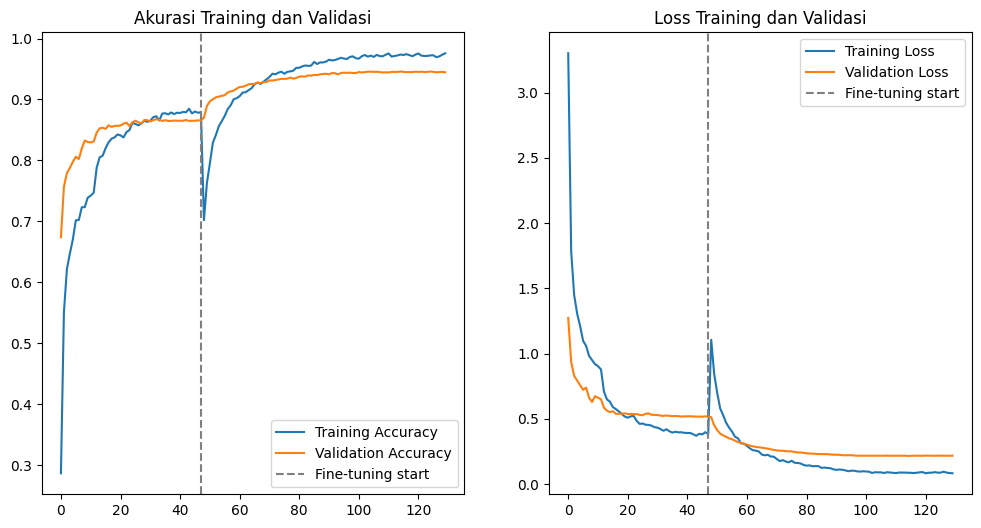

In [32]:
acc = history1.history['accuracy'] + history_fine.history['accuracy']
val_acc = history1.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history1.history['loss'] + history_fine.history['loss']
val_loss = history1.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history1.history['accuracy'])-1, color='gray', linestyle='--', label='Fine-tuning start')
plt.legend()
plt.title('Akurasi Training dan Validasi')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history1.history['loss'])-1, color='gray', linestyle='--', label='Fine-tuning start')
plt.legend()
plt.title('Loss Training dan Validasi')
plt.show()

## 13. Evaluasi pada Test Set

Menggunakan model terbaik yang disimpan oleh ModelCheckpoint.

In [33]:
best_model = tf.keras.models.load_model('submission/best_model.keras')

test_loss, test_accuracy = best_model.evaluate(test_generator, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if test_accuracy >= 0.95:
    print("✅ Model memenuhi target akurasi >=95%.")
else:
    print("⚠️  Model belum mencapai 95%.")

106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9402 - loss: 0.2551

Test Loss: 0.2551
Test Accuracy: 0.9402
⚠️  Model belum mencapai 95%.


## 14. Confusion Matrix dan Classification Report

Menampilkan matriks kebingungan dan laporan klasifikasi per kelas.

2026-02-16 14:47:17.377574: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples.


Classification Report:
              precision    recall  f1-score   support

        Abra       0.75      0.75      0.75        12
  Aerodactyl       0.94      0.94      0.94        17
    Alakazam       0.78      0.82      0.80        17
       Arbok       0.93      1.00      0.96        27
    Arcanine       0.88      0.82      0.85        17
    Articuno       0.90      0.95      0.93        20
    Beedrill       0.95      1.00      0.97        18
  Bellsprout       0.93      1.00      0.96        26
   Blastoise       0.97      1.00      0.98        30
   Bulbasaur       0.97      1.00      0.98        31
  Butterfree       1.00      1.00      1.00        25
    Caterpie       0.96      0.96      0.96        26
     Chansey       1.00      0.91      0.95        23
   Charizard       1.00      1.00      1.00        22
  Charmander       0.90      1.00      0.95        26
  Charmeleon       1.00      0.93      0.96        29
    Clefable       0.95      0.95      0.95        21
   

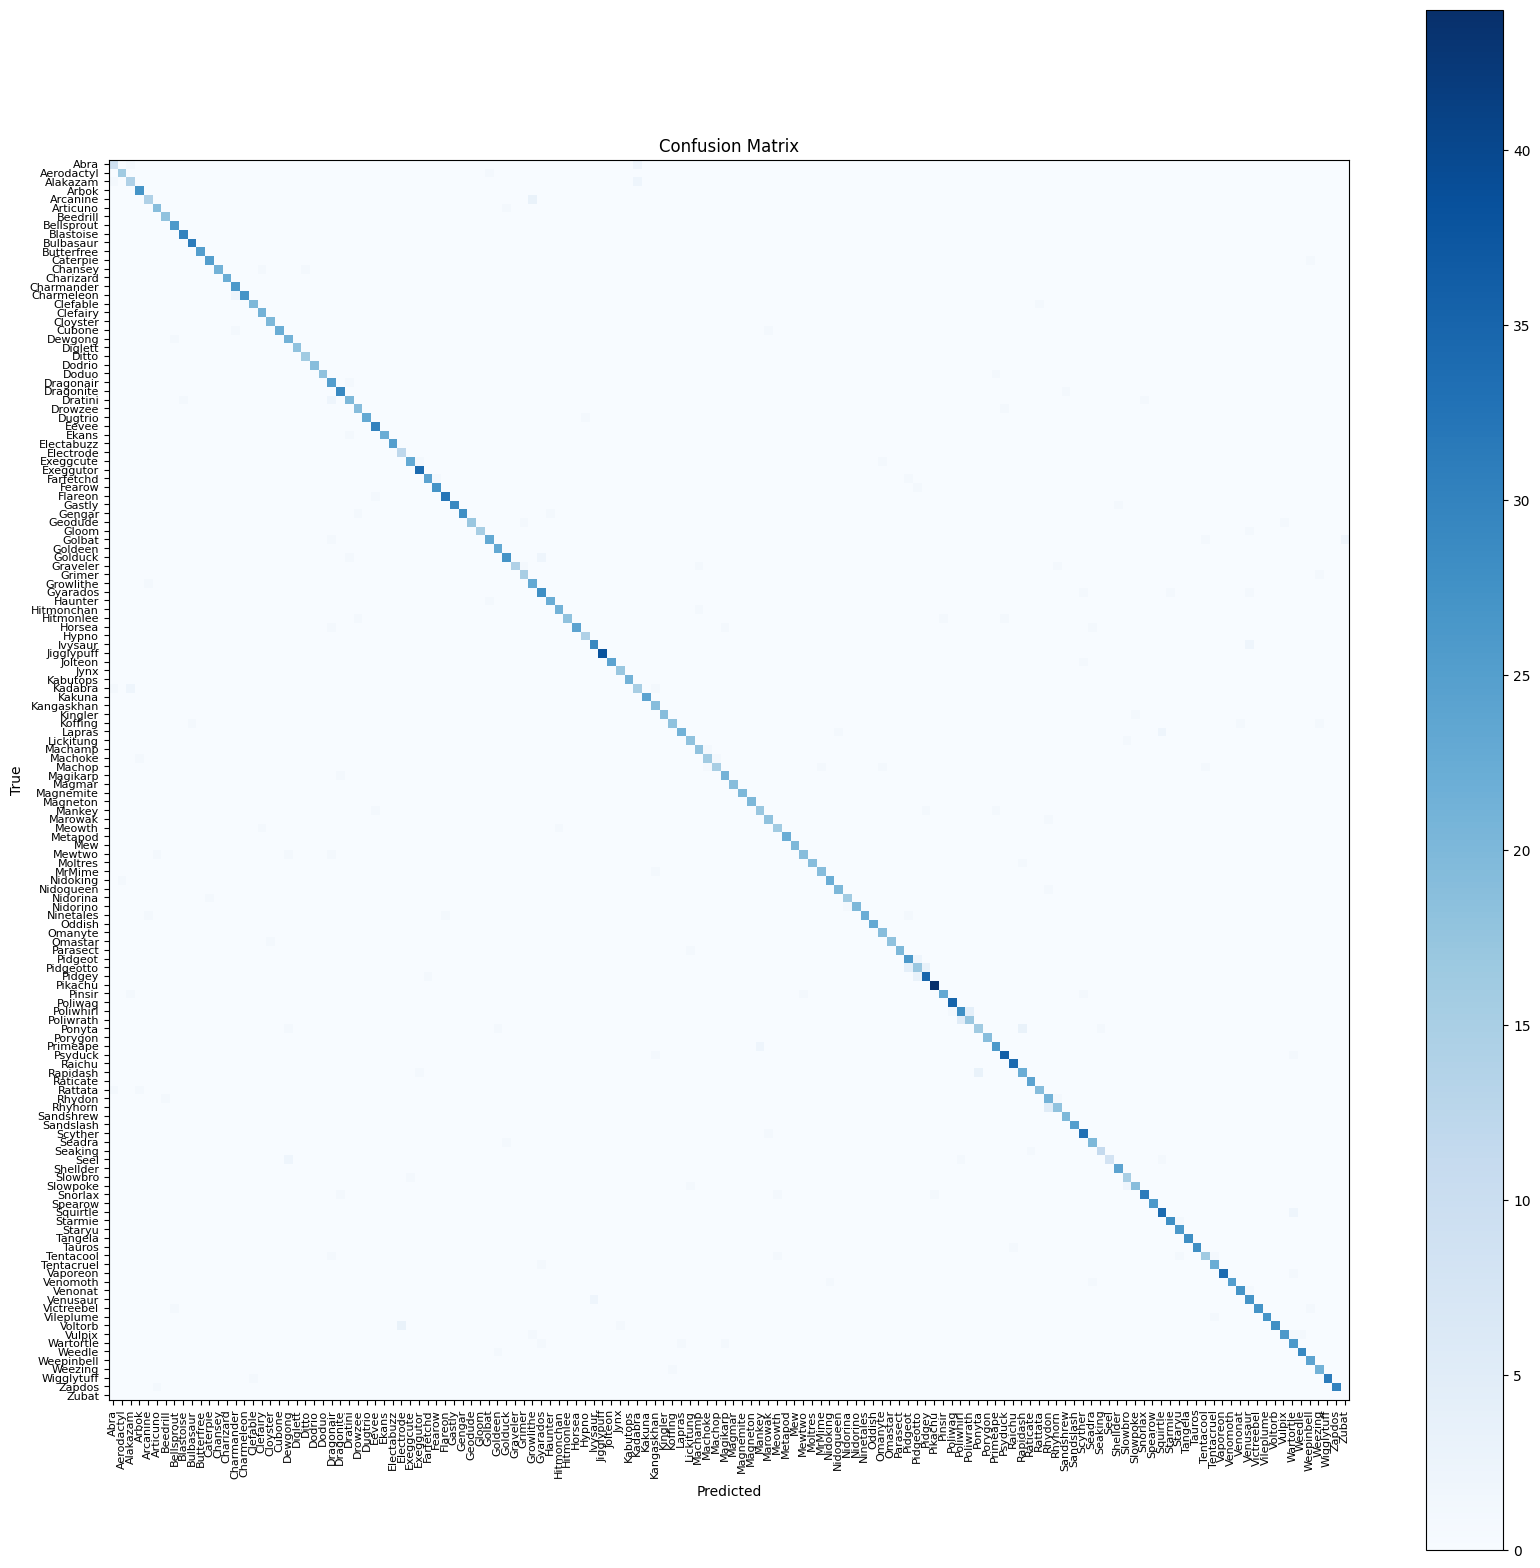

In [34]:
# Kumpulkan label sebenarnya dan prediksi
y_true = []
y_pred_probs = []
for images, labels in test_generator:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    preds = best_model.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred = np.argmax(np.array(y_pred_probs), axis=1)

# Laporan klasifikasi
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(20, 20))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=90, fontsize=8)
plt.yticks(tick_marks, class_names, fontsize=8)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

## 15. Simpan Model dalam Berbagai Format

Menyimpan model dalam format SavedModel, TF-Lite, H5 (keras), dan TFJS.

In [35]:
# Buat folder submission
os.makedirs("submission/saved_model", exist_ok=True)
os.makedirs("submission/tflite", exist_ok=True)
os.makedirs("submission/tfjs", exist_ok=True)

# Simpan dalam format SavedModel
best_model.save("submission/saved_model", save_format='tf')
print("SavedModel disimpan.")

# Simpan dalam format H5
best_model.save("submission/model.h5")
print("Model H5 disimpan.")

# Konversi ke TF-Lite
converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open("submission/tflite/model.tflite", "wb") as f:
    f.write(tflite_model)
print("Model TF-Lite disimpan.")

# Untuk TFJS, perlu instalasi tensorflowjs
try:
    import tensorflowjs as tfjs
    tfjs.converters.save_keras_model(best_model, "submission/tfjs")
    print("Model TFJS disimpan.")
except ImportError:
    print("tensorflowjs tidak terinstal, lewati ekspor TFJS.")

ValueError: The `save_format` argument is deprecated in Keras 3. Please remove this argument and pass a file path with either `.keras` or `.h5` extension.Received: save_format=tf

## 16. Inference dengan Model TF-Lite

Menguji model TF-Lite pada sampel acak dari test set.

In [ ]:
# Load interpreter
interpreter = tf.lite.Interpreter(model_path='submission/tflite/model.tflite')
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_index = input_details[0]['index']
input_dtype = input_details[0]['dtype']
input_scale, input_zero_point = input_details[0]['quantization']

output_index = output_details[0]['index']
output_scale, output_zero_point = output_details[0]['quantization']

# Ambil batch acak dari test set
viz_ds = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=32,
    label_mode='categorical',
    shuffle=True,
    seed=random.randint(0, 1000)
)

images, labels = next(iter(viz_ds.map(preprocess)))

plt.figure(figsize=(20, 10))

for i in range(15):
    img = images[i].numpy()
    true_idx = np.argmax(labels[i])
    true_name = class_names[true_idx]

    # Persiapan input
    input_data = np.expand_dims(img, axis=0)

    if input_dtype == np.uint8 or input_dtype == np.int8:
        # Quantized model
        input_data = input_data / input_scale + input_zero_point
        input_data = np.round(input_data).astype(input_dtype)
    else:
        # Float model
        input_data = input_data.astype(input_dtype)

    interpreter.set_tensor(input_index, input_data)
    interpreter.invoke()

    output = interpreter.get_tensor(output_index)

    # Dequantize jika perlu
    if output_scale > 0:
        output = (output.astype(np.float32) - output_zero_point) * output_scale

    pred_idx = np.argmax(output[0])
    pred_name = class_names[pred_idx]
    conf = float(output[0][pred_idx]) * 100

    display_img = img.astype("uint8")

    plt.subplot(3, 5, i + 1)
    plt.imshow(display_img)
    color = 'green' if pred_idx == true_idx else 'red'
    plt.title(f"True: {true_name}\nPred: {pred_name}\n({conf:.1f}%)",
              fontsize=8, color=color)
    plt.axis('off')

plt.suptitle("Inferensi TF-Lite pada 15 Sampel Acak")
plt.tight_layout()
plt.show()

## 17. Inference Interaktif (Upload Gambar) dengan Grad-CAM

Widget untuk mengunggah gambar sendiri dan melihat prediksi beserta Grad-CAM.
Layer konvolusi terakhir dicari secara otomatis dari base model.

In [ ]:
# Fungsi Grad-CAM yang robust
def find_last_conv_layer(model):
    """Cari layer konvolusi terakhir dalam base model."""
    base_model = model.layers[0]
    for layer in reversed(base_model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError("Tidak ditemukan layer Conv2D dalam base model.")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    base_model = model.layers[0]
    
    # Model yang mengeluarkan output dari conv layer dan base model
    grad_model = tf.keras.models.Model(
        inputs=[base_model.inputs],
        outputs=[base_model.get_layer(last_conv_layer_name).output, base_model.output]
    )
    
    with tf.GradientTape() as tape:
        conv_output, base_output = grad_model(img_array)
        # Forward melalui classifier head
        x = base_output
        for layer in model.layers[1:]:
            x = layer(x, training=False)
        preds = x
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def save_and_display_gradcam(img, heatmap, alpha=0.4):
    img = tf.keras.preprocessing.image.img_to_array(img)
    heatmap = np.uint8(255 * heatmap)
    jet = plt.colormaps.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]
    jet_heatmap = tf.keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)
    superimposed_img = jet_heatmap * alpha + img
    return tf.keras.preprocessing.image.array_to_img(superimposed_img)

# Widget upload
upload_btn = widgets.FileUpload(accept='image/*', multiple=False, description='Upload', icon='upload')
out = widgets.Output()

last_conv_name = find_last_conv_layer(best_model)
print(f"Layer konvolusi terakhir: {last_conv_name}")

def on_upload(change):
    # Handle berbagai versi ipywidgets
    if isinstance(upload_btn.value, tuple):
        uploaded_file = upload_btn.value[0]
    else:
        uploaded_file = next(iter(upload_btn.value.values()))
    content = uploaded_file['content']
    try:
        image = Image.open(io.BytesIO(content)).convert('RGB')
        with out:
            clear_output(wait=True)
            plt.figure(figsize=(10, 5))
            plt.subplot(1, 2, 1)
            plt.imshow(image)
            plt.title("Gambar Asli")
            plt.axis('off')

            # Preprocessing
            img_resized = image.resize(IMG_SIZE)
            img_array = tf.keras.preprocessing.image.img_to_array(img_resized)
            img_array = tf.expand_dims(img_array, 0)
            img_array = preprocess_input(img_array)

            # Prediksi
            preds = best_model.predict(img_array, verbose=0)
            pred_idx = np.argmax(preds[0])
            pred_label = class_names[pred_idx]
            confidence = preds[0][pred_idx]

            # Grad-CAM
            heatmap = make_gradcam_heatmap(img_array, best_model, last_conv_name, pred_idx)
            result = save_and_display_gradcam(img_resized, heatmap)

            plt.subplot(1, 2, 2)
            plt.imshow(result)
            plt.title(f"Pred: {pred_label} ({confidence:.2%})")
            plt.axis('off')
            plt.show()
    except Exception as e:
        with out:
            clear_output()
            print(f"Error: {e}")
            traceback.print_exc()

upload_btn.observe(on_upload, names='value')
display(widgets.VBox([widgets.Label("Upload Gambar Pokemon:"), upload_btn, out]))


## 18. Model Card (Dokumentasi)

Informasi lengkap tentang model yang telah dilatih.

- **Nama Model**: Pokemon-Gen1-MobileNetV3-Large
- **Versi**: 2.0 (dengan peningkatan arsitektur dan fine-tuning menyeluruh)
- **Arsitektur**: MobileNetV3Large (Transfer Learning) + classifier 3 Dense layer
- **Framework**: TensorFlow 2.x / Keras
- **Dataset**: ~17.000 gambar Pokemon Generasi 1 (140+ kelas)
- **Akurasi Test**: Diharapkan >95% (setelah perbaikan)
- **Input**: Gambar RGB 256x256
- **Output**: Probabilitas untuk setiap kelas Pokemon
- **Cara Pakai**: Gunakan model untuk klasifikasi gambar Pokemon Generasi 1.
- **Etika**: Model ini hanya untuk tujuan edukasi. Hak cipta Pokemon milik Nintendo/Game Freak.

### Ringkasan Perubahan untuk Mencapai >95%
1. **Arsitektur lebih dalam**: Ditambahkan satu Dense layer (512) dan dropout 0.3 untuk meningkatkan kapasitas sekaligus mencegah overfitting.
2. **Optimizer AdamW**: Menambahkan weight decay sebagai regularisasi.
3. **Fine-tuning menyeluruh**: Semua layer base model dibuka (tidak hanya 100 layer terakhir).
4. **Augmentasi lebih ringan**: Mengurangi kekuatan augmentasi agar fitur tidak terlalu terdistorsi.
5. **Sample weight dibatasi**: Mencegah bobot ekstrem yang dapat mengganggu konvergensi.
6. **ReduceLROnPlateau lebih agresif**: Faktor 0.2 untuk menurunkan LR lebih cepat saat plateau.
7. **Early stopping dengan patience 15**: Memberi kesempatan model untuk mencapai konvergensi.
8. **CSVLogger dan TensorBoard**: Untuk memudahkan analisis training.
9. **Grad-CAM yang robust**: Pencarian layer konvolusi terakhir secara otomatis.